# First coupled HiRO-ACE → discharge run — diagnostics

Two `run_predict.py` runs over the same 10-year HiRO-ACE trajectory (`ic0000`/m0), 962 gauged
catchments, 3,200 days, differing only in how the forcing is normalized
(`hydro/pipeline/README.md` §5.1):

| run | `x_mean`/`x_std` from | `y_std` |
|---|---|---|
| **frozen** | the training data (real MSM/GARADAR) | training |
| **forcing** | the HiRO-ACE forcing itself | training |

Compared against observed discharge **distributionally** — HiRO-ACE is a scenario, not a reanalysis
of 2014–2023, so its dates carry no meaning and a date-matched score would measure calendar
coincidence, not skill.

**Question this notebook answers:** the aggregate predicted hydrograph peaks in spring while the
observed one peaks in July. Is that a rainfall problem (visible in the forcing itself), a snowmelt
problem, or an artefact of which catchments dominate the average?

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

DATA = Path("/Users/valentin/Desktop/UNRISK/Projects/coupled_model/climate-hydro-pipeline-data")
RUN = DATA / "hydro/results/coupled_run_2026-09-23"
FORCING = DATA / "processing/catchment_weighting/data/hiroace_dynamic_ic0000_full10yr_m0_v2.zarr"

SURFACE, INK, INK2, INK3 = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8983"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"   # dataviz palette slots 1-4
plt.rcParams.update({"figure.dpi": 130, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
                     "axes.edgecolor": INK3, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True,
                     "grid.color": "#e6e5e0", "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9})

def style(ax, title=None, ylabel=None, xlabel=None):
    if title: ax.set_title(title, color=INK, fontsize=11, fontweight="bold", loc="left", pad=10)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.set_axisbelow(True)
    return ax

MONTHS = list("JFMAMJJASOND")
x = np.arange(12)

## Load — and align on catchment ID

**Trap worth naming:** the prediction and observation files store catchments in *different orders*.
Indexing them positionally silently compares unrelated rivers (it made small headwater catchments
look over-predicted 5×). Everything below is aligned by label first.

In [2]:
obs = xr.open_dataset(RUN / "observed_discharge_gauged.nc")["discharge_obs"].transpose("spatial", "time")
nodes = obs["spatial"].values
pred_fr = xr.open_dataset(RUN / "predictions_hiroace_full10yr_m0_frozen.nc")["discharge_pred"]
pred_fo = xr.open_dataset(RUN / "predictions_hiroace_full10yr_m0.nc")["discharge_pred"]
print("stored in the same order?", np.array_equal(pred_fr["spatial"].values, nodes))
pred_fr = pred_fr.sel(spatial=nodes)      # align by label
pred_fo = pred_fo.sel(spatial=nodes)
assert np.array_equal(pred_fr["spatial"].values, nodes)

meta = pd.read_csv(RUN / "gauged_catchment_meta.csv").set_index("node").loc[nodes]
flags = pd.read_csv(RUN / "catchment_training_flags.csv").set_index("node").loc[nodes]
real_forcing = pd.read_csv(RUN / "real_forcing_daily_gauged.csv", parse_dates=["time"]).set_index("time")
north = meta["lat"].values >= 37
in_training = flags["in_training"].values
print(f"catchments {len(nodes)} | northern (>=37N) {north.sum()} | dam-free, i.e. model was trained on them: {in_training.sum()}")

fds = xr.open_zarr(FORCING, consolidated=None).sel(spatial=nodes)
hiro_temp = np.mean([fds[f"hiroace_temp_4h_bin_{n}"].values for n in range(6)], axis=0)
hiro_prcp = np.mean([fds[f"hiroace_prcp_4h_bin_{n}"].values for n in range(6)], axis=0) * 24   # mm/day
hiro_time = pd.DatetimeIndex(fds["time"].values)

def monthly(values, times, mask=None):
    v = np.asarray(values)
    if v.shape[0] != len(times): v = v.T          # -> (time, catchment)
    if mask is not None: v = v[:, mask]
    d = pd.DataFrame(v, index=pd.DatetimeIndex(times))
    return d.groupby(d.index.month).mean().mean(axis=1).reindex(range(1, 13)).values

m_obs, m_fr, m_fo = (monthly(a.values, a["time"].values) for a in (obs, pred_fr, pred_fo))
m_hiro_p, m_hiro_t = monthly(hiro_prcp, hiro_time), monthly(hiro_temp, hiro_time)
m_real_p = real_forcing["garadar_prcp_daily"].groupby(real_forcing.index.month).mean().values
m_real_t = real_forcing["msm_temp_daily"].groupby(real_forcing.index.month).mean().values

stored in the same order? False
catchments 962 | northern (>=37N) 399 | dam-free, i.e. model was trained on them: 318


## 1. Discharge seasonal cycle

The normalization choice moves the *level* (frozen is far closer) but not the *shape*, so the
timing error is inherited from the forcing rather than created by normalization.

peak month — observed: 7 | frozen: 4


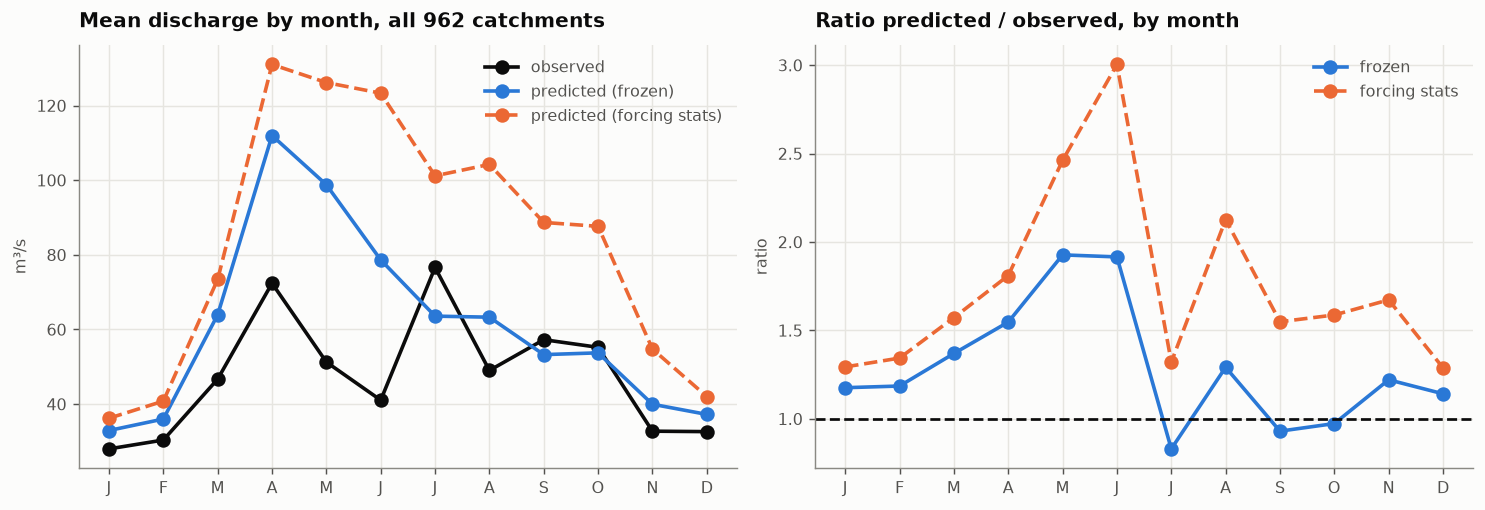

In [3]:
fig, (ax, bx) = plt.subplots(1, 2, figsize=(11.5, 4))
for a in (ax, bx):
    a.set_xticks(x); a.set_xticklabels(MONTHS)
ax.plot(x, m_obs, "o-", color=INK, lw=2, ms=7, label="observed")
ax.plot(x, m_fr, "o-", color=BLUE, lw=2, ms=7, label="predicted (frozen)")
ax.plot(x, m_fo, "o--", color=ORANGE, lw=2, ms=7, label="predicted (forcing stats)")
style(ax, "Mean discharge by month, all 962 catchments", "m³/s")
ax.legend(frameon=False, labelcolor=INK2)

bx.plot(x, m_fr / m_obs, "o-", color=BLUE, lw=2, ms=7, label="frozen")
bx.plot(x, m_fo / m_obs, "o--", color=ORANGE, lw=2, ms=7, label="forcing stats")
bx.axhline(1, color=INK, lw=1.5, ls="--")
style(bx, "Ratio predicted / observed, by month", "ratio")
bx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()
print("peak month — observed:", int(np.argmax(m_obs)) + 1, "| frozen:", int(np.argmax(m_fr)) + 1)

## 2. Does the forcing explain it?

If the discharge error is inherited, it should be visible in the precipitation that drives it.

precip peak month: real 7 | HiRO-ACE 6
annual precip HiRO/real: 0.852
Jul-Sep precip ratio:   [0.58 0.72 0.61]


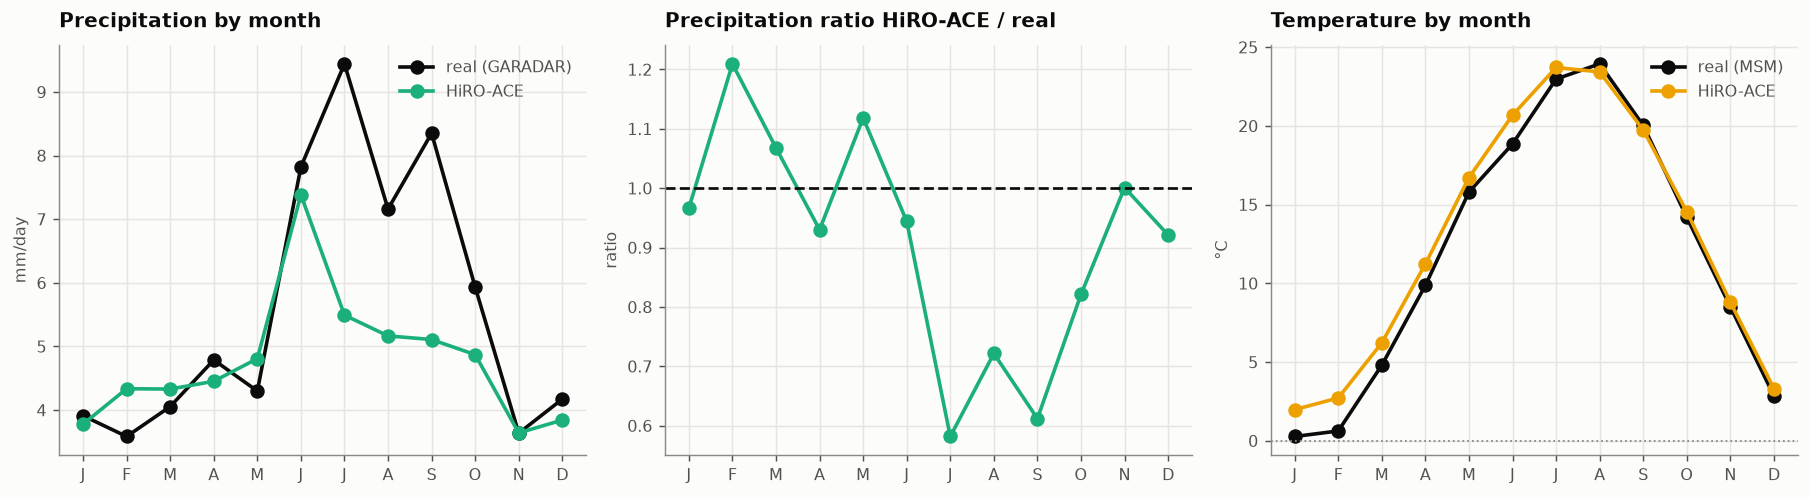

In [4]:
fig, (ax, bx, cx) = plt.subplots(1, 3, figsize=(14, 3.9))
for a in (ax, bx, cx):
    a.set_xticks(x); a.set_xticklabels(MONTHS)
ax.plot(x, m_real_p, "o-", color=INK, lw=2, ms=7, label="real (GARADAR)")
ax.plot(x, m_hiro_p, "o-", color=AQUA, lw=2, ms=7, label="HiRO-ACE")
style(ax, "Precipitation by month", "mm/day"); ax.legend(frameon=False, labelcolor=INK2)

bx.plot(x, m_hiro_p / m_real_p, "o-", color=AQUA, lw=2, ms=7)
bx.axhline(1, color=INK, lw=1.5, ls="--")
style(bx, "Precipitation ratio HiRO-ACE / real", "ratio")

cx.plot(x, m_real_t, "o-", color=INK, lw=2, ms=7, label="real (MSM)")
cx.plot(x, m_hiro_t, "o-", color=YELLOW, lw=2, ms=7, label="HiRO-ACE")
cx.axhline(0, color=INK3, lw=1, ls=":")
style(cx, "Temperature by month", "°C"); cx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()

print("precip peak month: real", int(np.argmax(m_real_p)) + 1, "| HiRO-ACE", int(np.argmax(m_hiro_p)) + 1)
print("annual precip HiRO/real:", round(m_hiro_p.mean() / m_real_p.mean(), 3))
print("Jul-Sep precip ratio:  ", np.round(m_hiro_p[6:9] / m_real_p[6:9], 2))

## 3. Who is the aggregate average actually describing?

Split two ways: geographically (snow-affected north vs rain-fed south) and by whether the model was
ever **trained** on the catchment — 644 of the 962 were excluded from training because they have a
dam upstream.

Northern (≥37°N)         obs peak  4 | pred peak  4 | annual ratio 1.35
Southern (<37°N)         obs peak  7 | pred peak  6 | annual ratio 1.19
Dam-free (trained on)    obs peak  7 | pred peak  4 | annual ratio 0.91
Dam-affected             obs peak  7 | pred peak  4 | annual ratio 1.32


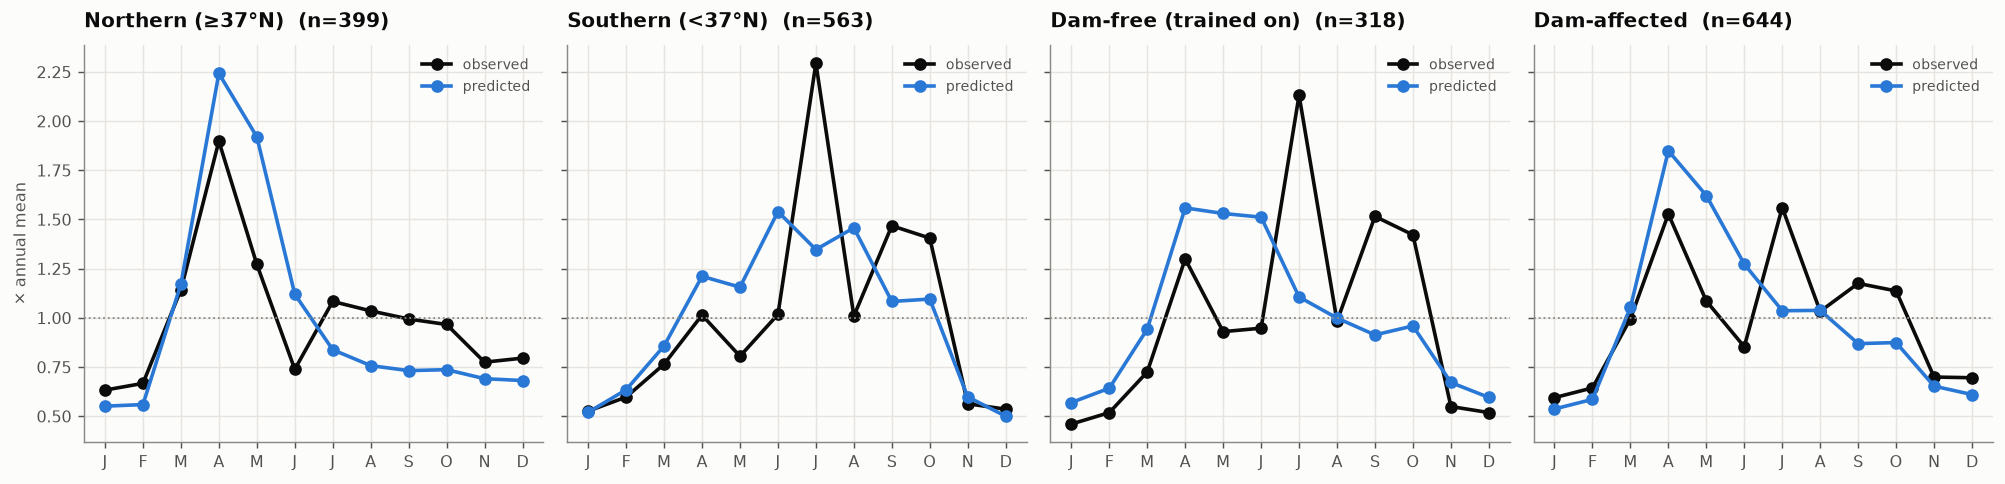

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 3.8), sharey=True)
groups = [("Northern (≥37°N)", north), ("Southern (<37°N)", ~north),
          ("Dam-free (trained on)", in_training), ("Dam-affected", ~in_training)]
for a, (name, mask) in zip(axes, groups):
    mo, mp = monthly(obs.values, obs["time"].values, mask), monthly(pred_fr.values, pred_fr["time"].values, mask)
    a.plot(x, mo / mo.mean(), "o-", color=INK, lw=2, ms=6, label="observed")
    a.plot(x, mp / mp.mean(), "o-", color=BLUE, lw=2, ms=6, label="predicted")
    a.axhline(1, color=INK3, lw=1, ls=":")
    a.set_xticks(x); a.set_xticklabels(MONTHS)
    style(a, f"{name}  (n={mask.sum()})", "× annual mean" if a is axes[0] else None)
    a.legend(frameon=False, labelcolor=INK2, fontsize=8)
    print(f"{name:24s} obs peak {int(np.argmax(mo))+1:2d} | pred peak {int(np.argmax(mp))+1:2d} "
          f"| annual ratio {mp.mean()/mo.mean():.2f}")
fig.tight_layout()

In [6]:
pm, om = np.nanmean(pred_fr.values, axis=1), np.nanmean(obs.values, axis=1)
ratio = pm / np.where(om > 0, om, np.nan)
ok = np.isfinite(ratio)
print(f"{'group':24s} {'median ratio':>13s} {'within +/-20%':>14s}")
for name, mask in groups + [("ALL", np.ones_like(north))]:
    s = mask.astype(bool) & ok
    print(f"{name:24s} {np.nanmedian(ratio[s]):13.2f} {100*np.mean(np.abs(ratio[s]-1) <= .2):13.0f}%")

group                     median ratio  within +/-20%
Northern (≥37°N)                  1.36            30%
Southern (<37°N)                  1.07            47%
Dam-free (trained on)             1.05            52%
Dam-affected                      1.30            34%
ALL                               1.20            40%


## 4. Flow-duration curves

Per catchment, then the median across catchments at each exceedance level, so one large river
cannot dominate.

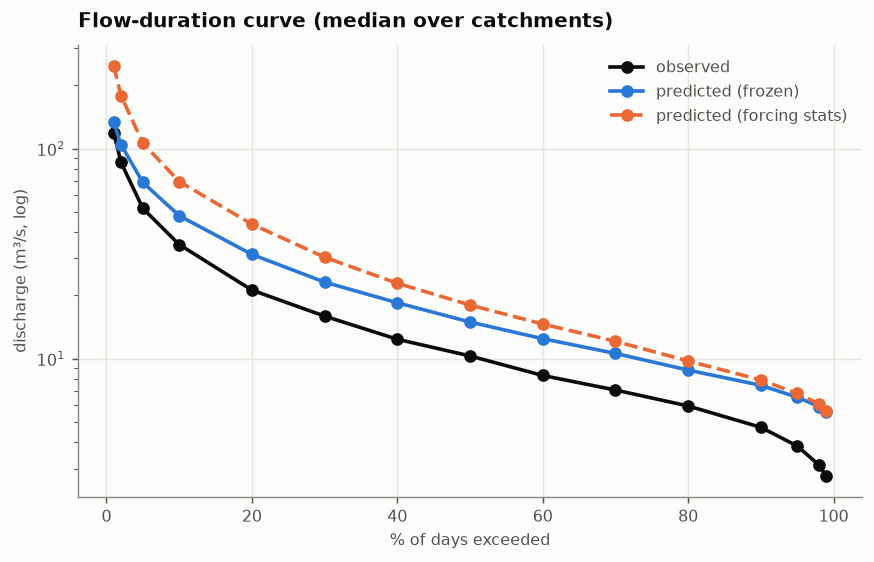

In [7]:
qs = np.array([0.01, 0.02, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99])
def fdc(arr):
    with np.errstate(invalid="ignore"):
        return np.nanmedian(np.nanquantile(arr, 1 - qs, axis=1), axis=1)

fig, ax = plt.subplots(figsize=(6.8, 4.4))
ax.plot(qs * 100, fdc(obs.values), "o-", color=INK, lw=2, ms=6, label="observed")
ax.plot(qs * 100, fdc(pred_fr.values), "o-", color=BLUE, lw=2, ms=6, label="predicted (frozen)")
ax.plot(qs * 100, fdc(pred_fo.values), "o--", color=ORANGE, lw=2, ms=6, label="predicted (forcing stats)")
ax.set_yscale("log")
style(ax, "Flow-duration curve (median over catchments)", "discharge (m³/s, log)", "% of days exceeded")
ax.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()

## 5. What CV is, and why it matters

**CV = standard deviation ÷ mean** — dimensionless, so it measures how *flashy* a river is
regardless of its size. Observed median is ~1.5: day-to-day swings are one and a half times the
average flow.

- **frozen stats** — level close, CV too low: the hydrograph is too smooth.
- **forcing stats** — CV almost exact, every flow inflated ≈1.7×: right shape, wrong scale.

Both follow from HiRO-ACE's precipitation standard deviation being only ~50–60% of the real one.

frozen  : median CV 1.20 (obs 1.53), mean-flow ratio 1.20, within +/-20%: 40%
forcing : median CV 1.51 (obs 1.53), mean-flow ratio 1.72, within +/-20%: 8%


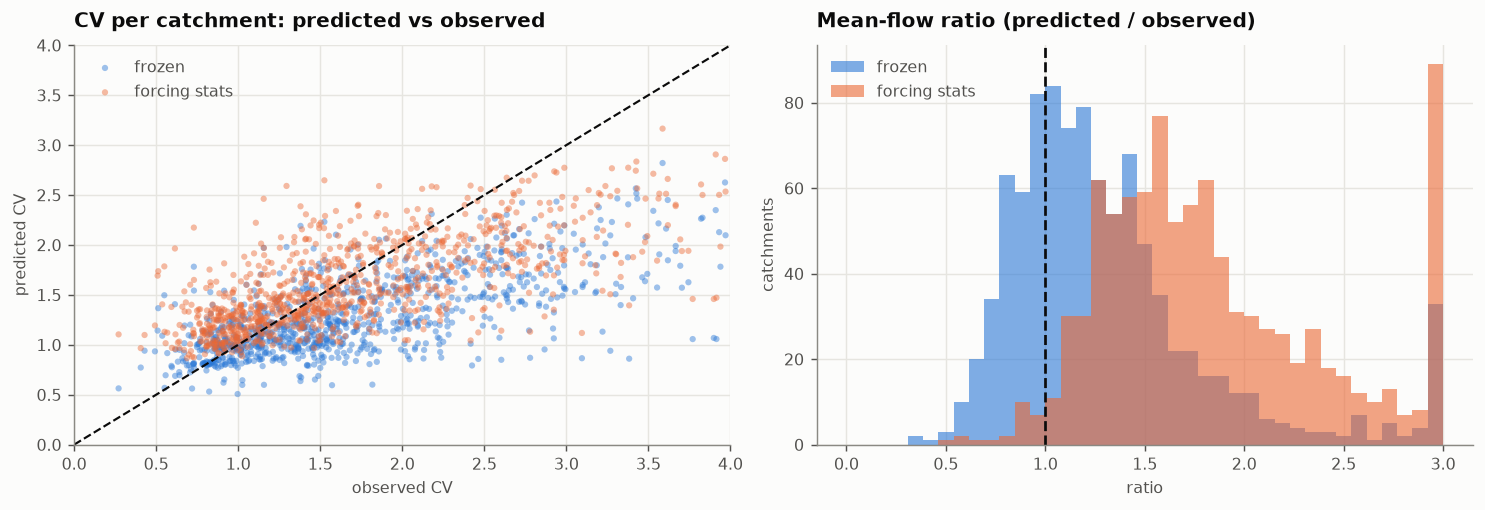

In [8]:
stats_fr = pd.read_csv(RUN / "pred_vs_obs_stats_frozen.csv")
stats_fo = pd.read_csv(RUN / "pred_vs_obs_stats.csv")
keep = (stats_fr["obs_n_valid"] >= 365) & (stats_fr["obs_mean"] > 0)

fig, (ax, bx) = plt.subplots(1, 2, figsize=(11.5, 4))
lim = [0, 4]
ax.scatter(stats_fr.loc[keep, "obs_cv"], stats_fr.loc[keep, "pred_cv"], s=12, alpha=.45,
           color=BLUE, edgecolors="none", label="frozen")
ax.scatter(stats_fo.loc[keep, "obs_cv"], stats_fo.loc[keep, "pred_cv"], s=12, alpha=.45,
           color=ORANGE, edgecolors="none", label="forcing stats")
ax.plot(lim, lim, color=INK, lw=1.2, ls="--")
ax.set_xlim(lim); ax.set_ylim(lim)
style(ax, "CV per catchment: predicted vs observed", "predicted CV", "observed CV")
ax.legend(frameon=False, labelcolor=INK2)

bins = np.linspace(0, 3, 40)
bx.hist(stats_fr.loc[keep, "ratio_mean"].clip(0, 3), bins=bins, color=BLUE, alpha=.6, label="frozen")
bx.hist(stats_fo.loc[keep, "ratio_mean"].clip(0, 3), bins=bins, color=ORANGE, alpha=.6, label="forcing stats")
bx.axvline(1, color=INK, lw=1.5, ls="--")
style(bx, "Mean-flow ratio (predicted / observed)", "catchments", "ratio")
bx.legend(frameon=False, labelcolor=INK2)
fig.tight_layout()

for nm, s in (("frozen", stats_fr), ("forcing", stats_fo)):
    d = s[keep]
    print(f"{nm:8s}: median CV {d['pred_cv'].median():.2f} (obs {d['obs_cv'].median():.2f}), "
          f"mean-flow ratio {d['ratio_mean'].median():.2f}, within +/-20%: "
          f"{100*((d['ratio_mean']-1).abs() <= .2).mean():.0f}%")

## Conclusions

1. **The spring peak is not snowmelt mistiming.** Northern, snow-affected catchments peak in April
   in *both* observation and prediction — the melt timing is right. The aggregate "April vs July"
   gap is mostly northern big rivers dominating an unweighted average.
2. **It is inherited from the precipitation.** HiRO-ACE's rainfall peaks in June against July in
   reality, and is drastically short in the late-summer rainy/typhoon season (Jul–Sep ratios
   ~0.58–0.72; annual 0.85). Discharge follows exactly: over-predicted May–June, under-predicted
   Jul–Oct.
3. **Dam-free catchments — the ones the model was actually trained on — are the best reproduced**
   (median ratio ≈1.05, about half within ±20%), while dam-affected ones sit ≈1.3. Reservoir
   regulation is not represented, which is expected rather than a defect.
4. **Variance, not just mean, is the headline forcing deficit** (§5). That is what a bias correction
   has to fix; a mean-only correction would leave the hydrograph too smooth.

**For bias correction:** quantile mapping applied **per calendar month** would address the seasonal
misplacement and the variance deficit together. A pooled, annual correction would fix neither.